## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 16.08.2024

Date of Last Modification: 17.08.2024

# 1. Setup

## 1.1 Libraries 

In [1]:
import torch
import os
import logging
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics



## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [2]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/simulated.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [3]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'input_ids'],
    num_rows: 8000
})

## 1.4 INIT distributed (it should change later)

In [4]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40317)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [5]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:Initializing learning rate scheduler: WarmupCosineSchedule
INFO:root:Initializing weight decay scheduler: CosineWDSchedule
INFO:root:Initializing automatic mixed precision training scaler: GradScaler
INFO:root:Epoch 1


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:[1,     0] loss: 0.519 masks: 324.0 20.0 [wd: 4.00e-02] [lr: 5.00e-05] [mem: 3.98e+03] (549.4 ms)
INFO:root:[1,     0] grad_stats: [1.03e-01 9.64e-02] (3.16e-04, 1.22e-01)
INFO:root:[1,    10] loss: 0.372 masks: 308.8 20.0 [wd: 4.00e-02] [lr: 4.97e-05] [mem: 4.26e+03] (91.3 ms)
INFO:root:[1,    10] grad_stats: [6.98e-03 6.85e-03] (2.30e-05, 8.69e-03)
INFO:root:[1,    20] loss: 0.342 masks: 307.0 20.0 [wd: 4.00e-02] [lr: 4.95e-05] [mem: 4.26e+03] (69.2 ms)
INFO:root:[1,    20] grad_stats: [3.94e-03 4.31e-03] (1.49e-05, 5.51e-03)
INFO:root:[1,    30] loss: 0.329 masks: 306.8 20.0 [wd: 4.00e-02] [lr: 4.92e-05] [mem: 4.26e+03] (61.6 ms)
INFO:root:[1,    30] grad_stats: [1.83e-03 2.01e-03] (8.51e-06, 2.57e-03)
INFO:root:[1,    40] loss: 0.321 masks: 306.9 20.0 [wd: 4.00e-02] [lr: 4.90e-05] [mem: 4.26e+03] (57.4 ms)
INFO:root:[1,    40] grad_stats: [1.73e-03 1.96e-03] (7.78e-06, 2.45e-03)
INFO:root:[1,    50] loss: 0.314 masks: 307.9 20.0 [wd: 4.01e-02] [lr: 4.88e-05] [mem: 4.26e+0

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [6]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 15 wit

400it [00:10, 38.30it/s]
100it [00:06, 15.06it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [7]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000002 , 0.9993043 , 0.9993415 , ..., 0.9993503 , 0.9992943 ,
        0.99933314],
       [0.9993043 , 0.99999976, 0.9994106 , ..., 0.9994527 , 0.9993781 ,
        0.9993738 ],
       [0.9993415 , 0.9994106 , 1.0000001 , ..., 0.999403  , 0.99930334,
        0.9993534 ],
       ...,
       [0.9993503 , 0.9994527 , 0.999403  , ..., 0.99999994, 0.9993656 ,
        0.9993993 ],
       [0.9992943 , 0.9993781 , 0.99930334, ..., 0.9993656 , 0.9999999 ,
        0.9992604 ],
       [0.99933314, 0.9993738 , 0.9993534 , ..., 0.9993993 , 0.9992604 ,
        1.        ]], dtype=float32)

### 3.1.2 Umap

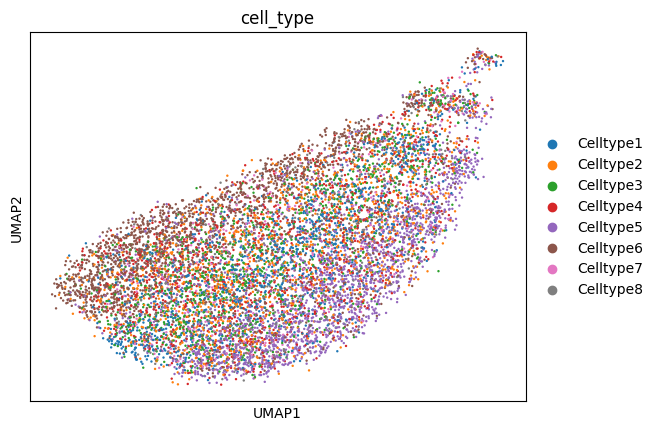

In [8]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [9]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.71
Test F1 Score: 0.69
Train Accuracy: 0.74
Train F1 Score: 0.72


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.711,
 'test_f1': 0.6854813260555479,
 'train_accuracy': 0.743,
 'train_f1': 0.7179862738529494}

### 3.1.4 KNeighborsClassifier

In [10]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.44
Test F1 Score: 0.36
Train Accuracy: 0.54
Train F1 Score: 0.48


{'test_accuracy': 0.4435,
 'test_f1': 0.36195609827594194,
 'train_accuracy': 0.5405,
 'train_f1': 0.48286140921578247}

### 3.1.5 nmi&ari

In [11]:
clustering_metrics(adata,label_col='cell_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
NMI (Normalized Mutual Information): 0.168698058873892
ARI (Adjusted Rand Index): 0.10300767072502677


{'nmi': 0.168698058873892, 'ari': 0.10300767072502677}

## 3.2 Cell Type CLS

In [12]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
398it [00:09, 42.17it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:10, 39.52it/s]
100it [00:02, 35.37it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [13]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000001 , 0.99999374, 0.9999906 , ..., 0.999967  , 0.9999672 ,
        0.9999349 ],
       [0.99999374, 1.        , 0.9999902 , ..., 0.99996644, 0.9999683 ,
        0.9999325 ],
       [0.9999906 , 0.9999902 , 0.9999998 , ..., 0.9999821 , 0.99994344,
        0.99996006],
       ...,
       [0.999967  , 0.99996644, 0.9999821 , ..., 1.0000001 , 0.99989164,
        0.99998146],
       [0.9999672 , 0.9999683 , 0.99994344, ..., 0.99989164, 0.9999998 ,
        0.999827  ],
       [0.9999349 , 0.9999325 , 0.99996006, ..., 0.99998146, 0.999827  ,
        1.        ]], dtype=float32)

### 3.2.2 Umap

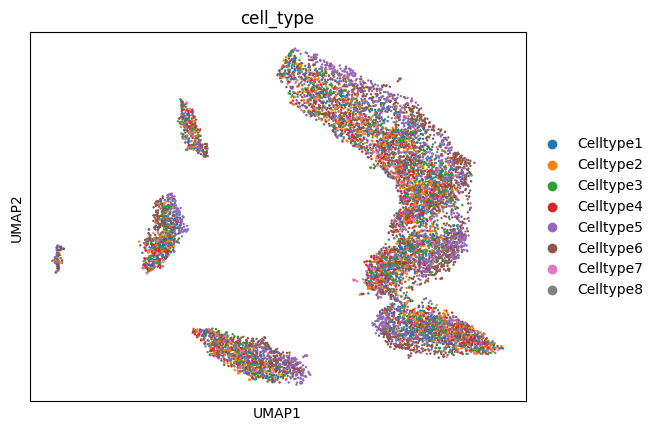

In [14]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [15]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.35
Test F1 Score: 0.24
Train Accuracy: 0.34
Train F1 Score: 0.23


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.3535,
 'test_f1': 0.24486115104850098,
 'train_accuracy': 0.337875,
 'train_f1': 0.2292843720313702}

### 3.2.4 KNeighborsClassifier

In [16]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.42
Test F1 Score: 0.42
Train Accuracy: 0.62
Train F1 Score: 0.62


{'test_accuracy': 0.4215,
 'test_f1': 0.4217740175732351,
 'train_accuracy': 0.62,
 'train_f1': 0.6150726001348756}

### 3.2.5 nmi&ari

In [17]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0017164034125009746
ARI (Adjusted Rand Index): 0.0003841837244149609


{'nmi': 0.0017164034125009746, 'ari': 0.0003841837244149609}

## 3.3 Cell Type weighted_average

In [18]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
396it [00:09, 42.18it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:09, 40.18it/s]
100it [00:02, 36.04it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [19]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.99999964, 0.99972415, 0.99962664, ..., 0.9973123 , 0.9996464 ,
        0.9985222 ],
       [0.99972415, 1.0000002 , 0.99970174, ..., 0.99763966, 0.9995982 ,
        0.99873275],
       [0.99962664, 0.99970174, 1.        , ..., 0.9982119 , 0.9993174 ,
        0.999129  ],
       ...,
       [0.9973123 , 0.99763966, 0.9982119 , ..., 0.9999999 , 0.9962939 ,
        0.99941576],
       [0.9996464 , 0.9995982 , 0.9993174 , ..., 0.9962939 , 1.0000002 ,
        0.9977131 ],
       [0.9985222 , 0.99873275, 0.999129  , ..., 0.99941576, 0.9977131 ,
        1.0000001 ]], dtype=float32)

### 3.3.2 Umap

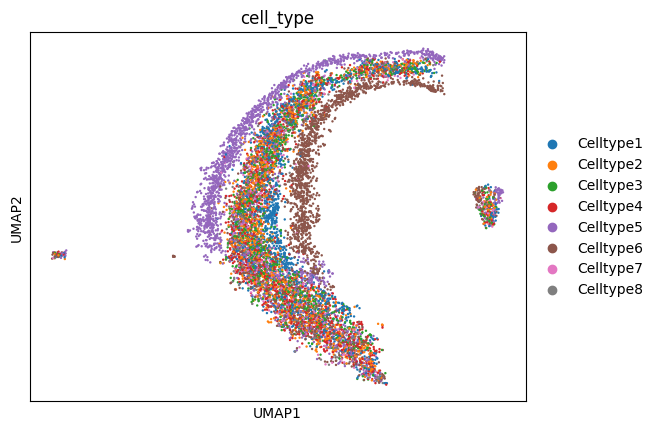

In [20]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [21]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.59
Test F1 Score: 0.58
Train Accuracy: 0.60
Train F1 Score: 0.59


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.59,
 'test_f1': 0.5848335026461698,
 'train_accuracy': 0.597,
 'train_f1': 0.5887359564548917}

### 3.3.4 KNN

In [22]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.57
Test F1 Score: 0.56
Train Accuracy: 0.69
Train F1 Score: 0.68


{'test_accuracy': 0.5725,
 'test_f1': 0.5616209611886448,
 'train_accuracy': 0.686375,
 'train_f1': 0.6772554284075631}

### 3.3.5 nmi&ari

In [23]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.011004531677753952
ARI (Adjusted Rand Index): 0.004858657012146912


{'nmi': 0.011004531677753952, 'ari': 0.004858657012146912}

## 3.4 Niche Type Average

In [24]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
399it [00:09, 42.17it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:10, 39.73it/s]
100it [00:02, 36.53it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [25]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.99992776, 0.99991393, ..., 0.9998654 , 0.99992275,
        0.9998323 ],
       [0.99992776, 1.0000001 , 0.9999244 , ..., 0.999872  , 0.99992335,
        0.99983585],
       [0.99991393, 0.9999244 , 1.        , ..., 0.9998704 , 0.9998908 ,
        0.99985623],
       ...,
       [0.9998654 , 0.999872  , 0.9998704 , ..., 1.0000002 , 0.99981344,
        0.99986446],
       [0.99992275, 0.99992335, 0.9998908 , ..., 0.99981344, 0.9999999 ,
        0.99975115],
       [0.9998323 , 0.99983585, 0.99985623, ..., 0.99986446, 0.99975115,
        0.99999994]], dtype=float32)

### 3.4.2 Umap

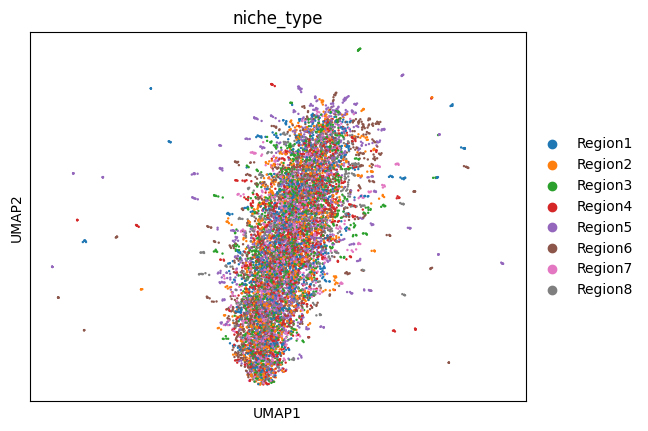

In [26]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [27]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.56
Test F1 Score: 0.52
Train Accuracy: 0.59
Train F1 Score: 0.55


{'test_accuracy': 0.56,
 'test_f1': 0.5170245303277138,
 'train_accuracy': 0.58875,
 'train_f1': 0.5495351348308951}

### 3.4.4 KNN

In [28]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.77
Test F1 Score: 0.77
Train Accuracy: 0.92
Train F1 Score: 0.92


{'test_accuracy': 0.772,
 'test_f1': 0.7744151883523942,
 'train_accuracy': 0.915375,
 'train_f1': 0.9157277900560091}

### 3.4.5 nmi&ari

In [29]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.0029271260159924707
ARI (Adjusted Rand Index): 0.0013311865058022812


{'nmi': 0.0029271260159924707, 'ari': 0.0013311865058022812}

## 3.5 Niche Type CLS

In [30]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
399it [00:09, 41.38it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:10, 39.77it/s]
100it [00:02, 38.24it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [31]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000001 , 0.99999374, 0.9999906 , ..., 0.999967  , 0.9999672 ,
        0.9999349 ],
       [0.99999374, 1.        , 0.9999902 , ..., 0.99996644, 0.9999683 ,
        0.9999325 ],
       [0.9999906 , 0.9999902 , 0.9999998 , ..., 0.9999821 , 0.99994344,
        0.99996006],
       ...,
       [0.999967  , 0.99996644, 0.9999821 , ..., 1.0000001 , 0.99989164,
        0.99998146],
       [0.9999672 , 0.9999683 , 0.99994344, ..., 0.99989164, 0.9999998 ,
        0.999827  ],
       [0.9999349 , 0.9999325 , 0.99996006, ..., 0.99998146, 0.999827  ,
        1.        ]], dtype=float32)

### 3.5.2 Umap

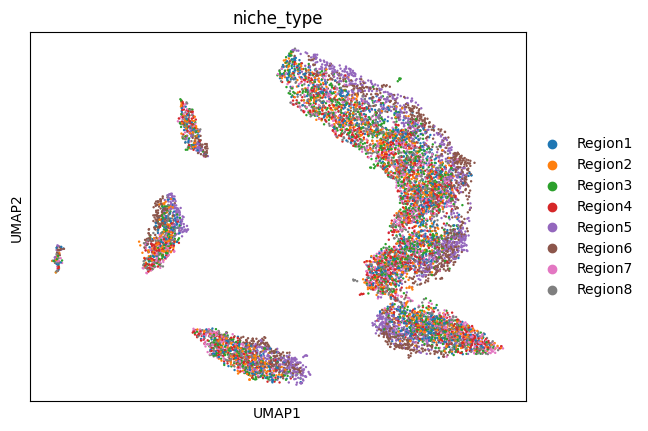

In [32]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [33]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.35
Test F1 Score: 0.26
Train Accuracy: 0.35
Train F1 Score: 0.26


{'test_accuracy': 0.3465,
 'test_f1': 0.25746664081849047,
 'train_accuracy': 0.349875,
 'train_f1': 0.2573577417438545}

### 3.5.4 KNN

In [34]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.53
Test F1 Score: 0.53
Train Accuracy: 0.76
Train F1 Score: 0.75


{'test_accuracy': 0.533,
 'test_f1': 0.5282236313351168,
 'train_accuracy': 0.755125,
 'train_f1': 0.7533557867120194}

### 3.5.5 nmi&ari

In [35]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.0028652160622062695
ARI (Adjusted Rand Index): 0.0012425962829668688


{'nmi': 0.0028652160622062695, 'ari': 0.0012425962829668688}

## 3.6 Niche Type weighted_average

In [36]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
396it [00:09, 41.51it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:10, 39.23it/s]
100it [00:02, 34.27it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [37]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.99999964, 0.99972415, 0.99962664, ..., 0.9973123 , 0.9996464 ,
        0.9985222 ],
       [0.99972415, 1.0000002 , 0.99970174, ..., 0.99763966, 0.9995982 ,
        0.99873275],
       [0.99962664, 0.99970174, 1.        , ..., 0.9982119 , 0.9993174 ,
        0.999129  ],
       ...,
       [0.9973123 , 0.99763966, 0.9982119 , ..., 0.9999999 , 0.9962939 ,
        0.99941576],
       [0.9996464 , 0.9995982 , 0.9993174 , ..., 0.9962939 , 1.0000002 ,
        0.9977131 ],
       [0.9985222 , 0.99873275, 0.999129  , ..., 0.99941576, 0.9977131 ,
        1.0000001 ]], dtype=float32)

### 3.6.2 Umap

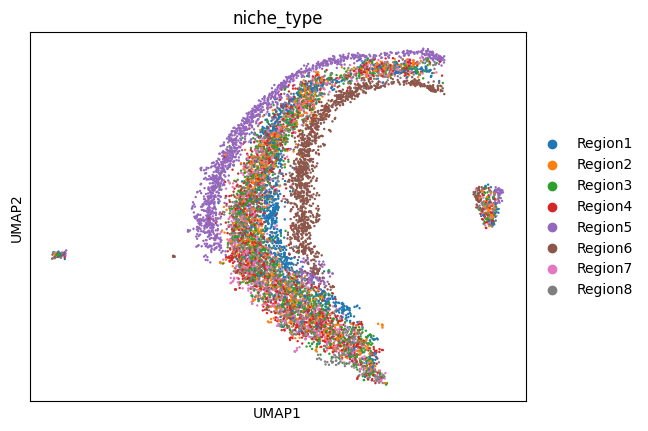

In [38]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [39]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.73
Test F1 Score: 0.71
Train Accuracy: 0.75
Train F1 Score: 0.72


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7335,
 'test_f1': 0.7125235988942275,
 'train_accuracy': 0.7485,
 'train_f1': 0.7246187391448526}

### 3.6.4 KNN

In [40]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.75
Test F1 Score: 0.74
Train Accuracy: 0.87
Train F1 Score: 0.87


{'test_accuracy': 0.75,
 'test_f1': 0.7397671203379511,
 'train_accuracy': 0.8685,
 'train_f1': 0.865304040832642}

### 3.6.5 nmi&ari

In [41]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.034117368410180794
ARI (Adjusted Rand Index): 0.017129949313253


{'nmi': 0.034117368410180794, 'ari': 0.017129949313253}

## 3.7 Retrieve Gene

In [42]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['emb']['gene_id']=332 #change this for different value to get different gene_emb
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
396it [00:10, 41.21it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:10, 38.00it/s]
100it [00:03, 32.55it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_total/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 3.7.1 Feature Analysis

In [69]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 1.0000001, ..., 0.       , 0.       ,
        0.9999306],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.9999306, ..., 0.       , 0.       ,
        1.0000001]], dtype=float32)

### 3.7.2 Umap

In [43]:
adata = adata[adata.obs['gene_count']!=0]

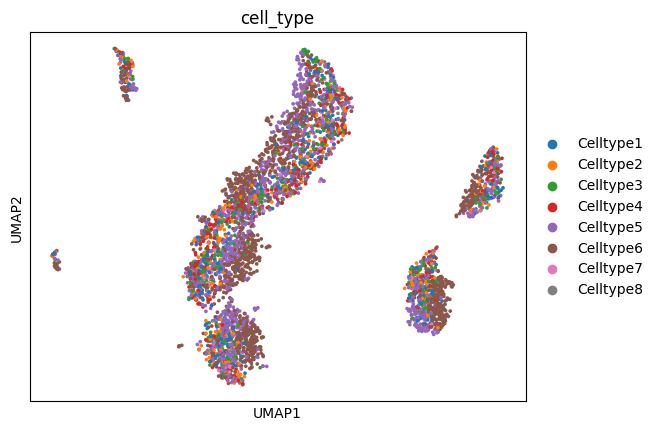

In [44]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

# 4.Model Training With just_cell as True

## 4.1 Train Model

In [45]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:[1,     0] loss: 0.522 masks: 285.0 20.0 [wd: 4.00e-02] [lr: 5.00e-05] [mem: 4.26e+03] (41.2 ms)
INFO:root:[1,     0] grad_stats: [1.12e-01 1.03e-01] (2.72e-04, 1.32e-01)
INFO:root:[1,    10] loss: 0.325 masks: 285.0 19.9 [wd: 4.00e-02] [lr: 4.97e-05] [mem: 4.26e+03] (28.5 ms)
INFO:root:[1,    10] grad_stats: [8.13e-03 7.84e-03] (2.12e-05, 1.02e-02)
INFO:root:[1,    20] loss: 0.280 masks: 285.0 19.9 [wd: 4.00e-02] [lr: 4.95e-05] [mem: 4.26e+03] (27.2 ms)
INFO:root:[1,    20] grad_stats: [2.36e-03 2.44e-03] (6.70e-06, 3.05e-03)
INFO:root:[1,    30] loss: 0.259 masks: 285.0 19.9 [wd: 4.00e-02] [lr: 4.92e-05] [mem: 4.26e+03] (26.8 ms)
INFO:root:[1,    30] grad_stats: [1.15e-03 1.15e-03] (3.79e-06, 1.48e-03)
INFO:root:[1,    40] loss: 0.248 masks: 285.0 19.9 [wd: 4.00e-02] [lr: 4.90e-05] [mem: 4.26e+03] (26.4 ms)
INFO:root:[1,    40] grad_stats: [8.91e-04 8.71e-04] (3.22e-06, 1.17e-03)
INFO:root:[1,    50] loss: 0.241 masks: 285.0 19.8 [wd: 4.01e-02] [lr: 4.88e-05] [mem: 4.26e+03

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:avg. loss 0.200
INFO:root:Epoch 2
INFO:root:[2,     0] loss: 0.180 masks: 285.0 19.0 [wd: 4.40e-02] [lr: 4.02e-05] [mem: 4.26e+03] (31.9 ms)
INFO:root:[2,     0] grad_stats: [6.59e-04 6.71e-04] (2.24e-06, 8.82e-04)
INFO:root:[2,    10] loss: 0.180 masks: 285.0 19.6 [wd: 4.42e-02] [lr: 3.99e-05] [mem: 4.26e+03] (28.4 ms)
INFO:root:[2,    10] grad_stats: [6.00e-04 6.10e-04] (2.14e-06, 7.71e-04)
INFO:root:[2,    20] loss: 0.180 masks: 285.0 19.7 [wd: 4.44e-02] [lr: 3.97e-05] [mem: 4.26e+03] (27.2 ms)
INFO:root:[2,    20] grad_stats: [6.86e-04 7.35e-04] (2.29e-06, 9.36e-04)
INFO:root:[2,    30] loss: 0.180 masks: 285.0 19.7 [wd: 4.46e-02] [lr: 3.94e-05] [mem: 4.26e+03] (26.7 ms)
INFO:root:[2,    30] grad_stats: [6.12e-04 6.65e-04] (2.12e-06, 8.44e-04)
INFO:root:[2,    40] loss: 0.179 masks: 285.0 19.7 [wd: 4.48e-02] [lr: 3.92e-05] [mem: 4.26e+03] (26.3 ms)
INFO:root:[2,    40] grad_stats: [6.56e-04 7.24e-04] (2.11e-06, 9.42e-04)
INFO:root:[2,    50] loss: 0.179 masks: 285.0 19.7 

# 5. Analysis With just_cell as True

## 5.1 Cell Type Average

In [46]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 15 wit

400it [00:04, 81.93it/s] 
100it [00:01, 66.27it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_total/extracted_features/cell_embedding_average.h5ad


### 5.1.1 Feature Analysis

In [47]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000002 , 0.9991183 , 0.9992162 , ..., 0.9992637 , 0.99927485,
        0.99929214],
       [0.9991183 , 1.0000001 , 0.9991994 , ..., 0.99920636, 0.9992786 ,
        0.99929017],
       [0.9992162 , 0.9991994 , 0.9999998 , ..., 0.99914414, 0.99922955,
        0.99919176],
       ...,
       [0.9992637 , 0.99920636, 0.99914414, ..., 1.        , 0.9992883 ,
        0.9992856 ],
       [0.99927485, 0.9992786 , 0.99922955, ..., 0.9992883 , 1.0000004 ,
        0.9992725 ],
       [0.99929214, 0.99929017, 0.99919176, ..., 0.9992856 , 0.9992725 ,
        0.9999999 ]], dtype=float32)

### 5.1.2 Umap

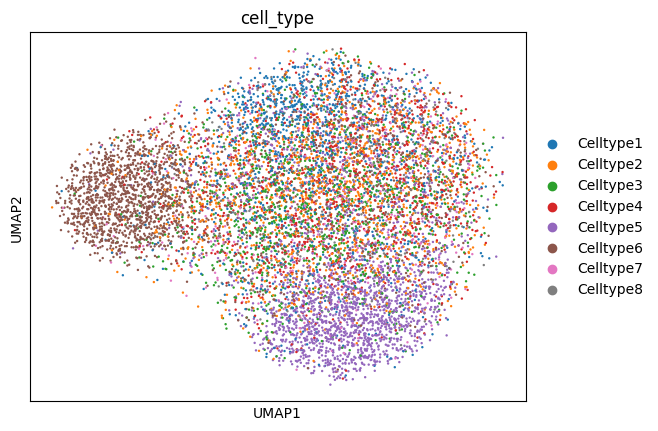

In [48]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.1.3 Logistic regression

In [49]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.76
Test F1 Score: 0.75
Train Accuracy: 0.81
Train F1 Score: 0.81


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7565,
 'test_f1': 0.7480190163235093,
 'train_accuracy': 0.81175,
 'train_f1': 0.8061312454237134}

### 5.1.4 KNN

In [50]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.49
Test F1 Score: 0.45
Train Accuracy: 0.64
Train F1 Score: 0.61


{'test_accuracy': 0.4865,
 'test_f1': 0.44589044994834465,
 'train_accuracy': 0.63825,
 'train_f1': 0.61208036907972}

### 5.1.5 nmi&ari

In [51]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.3286290391496063
ARI (Adjusted Rand Index): 0.2908593861899674


{'nmi': 0.3286290391496063, 'ari': 0.2908593861899674}

## 5.2 Cell Type CLS

In [52]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
398it [00:03, 164.01it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:03, 110.43it/s]
100it [00:01, 99.04it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_total/extracted_features/cell_embedding_cls.h5ad


### 5.2.1 Feature Analysis

In [53]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.99999994, 0.9999412 , 0.9999504 , ..., 0.99986917, 0.99995196,
        0.9999571 ],
       [0.9999412 , 0.99999976, 0.9999485 , ..., 0.9998644 , 0.9999449 ,
        0.9999548 ],
       [0.9999504 , 0.9999485 , 1.0000001 , ..., 0.99986523, 0.99994415,
        0.9999521 ],
       ...,
       [0.99986917, 0.9998644 , 0.99986523, ..., 1.0000001 , 0.9998939 ,
        0.99986815],
       [0.99995196, 0.9999449 , 0.99994415, ..., 0.9998939 , 1.        ,
        0.9999485 ],
       [0.9999571 , 0.9999548 , 0.9999521 , ..., 0.99986815, 0.9999485 ,
        1.        ]], dtype=float32)

### 5.2.2 Umap

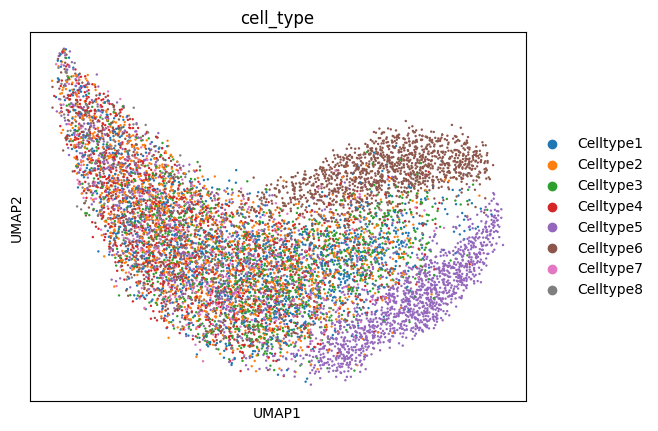

In [54]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.2.3 Logistic regression

In [55]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.54
Test F1 Score: 0.51
Train Accuracy: 0.53
Train F1 Score: 0.51


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.5365,
 'test_f1': 0.5111406132054878,
 'train_accuracy': 0.534125,
 'train_f1': 0.5086854334535444}

### 5.2.4 KNN

In [56]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.47
Test F1 Score: 0.46
Train Accuracy: 0.64
Train F1 Score: 0.64


{'test_accuracy': 0.471,
 'test_f1': 0.46167509902919257,
 'train_accuracy': 0.642625,
 'train_f1': 0.6352921330188499}

### 5.2.5 nmi&ari

In [57]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.10666010971018257
ARI (Adjusted Rand Index): 0.04485369011960204


{'nmi': 0.10666010971018257, 'ari': 0.04485369011960204}

## 5.3 Cell Type weighted_average

In [58]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
382it [00:03, 152.27it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:03, 116.41it/s]
100it [00:01, 84.37it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_total/extracted_features/cell_embedding_weighted_average.h5ad


### 5.3.1 Feature Analysis

In [59]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.9999999 , 0.9989464 , 0.9989655 , ..., 0.9990396 , 0.9990722 ,
        0.9990153 ],
       [0.9989464 , 1.        , 0.9989509 , ..., 0.9989677 , 0.9989768 ,
        0.99900925],
       [0.9989655 , 0.9989509 , 1.0000001 , ..., 0.9988599 , 0.9989915 ,
        0.99885905],
       ...,
       [0.9990396 , 0.9989677 , 0.9988599 , ..., 0.99999964, 0.99910134,
        0.9989871 ],
       [0.9990722 , 0.9989768 , 0.9989915 , ..., 0.99910134, 1.        ,
        0.99900603],
       [0.9990153 , 0.99900925, 0.99885905, ..., 0.9989871 , 0.99900603,
        0.9999998 ]], dtype=float32)

### 5.3.2 Umap

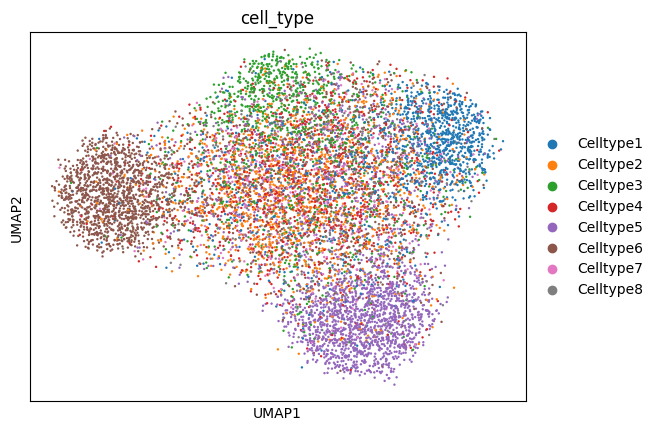

In [60]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.3.3 Logistic regression

In [61]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.83
Test F1 Score: 0.82
Train Accuracy: 0.88
Train F1 Score: 0.88


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.8295,
 'test_f1': 0.8235013493212857,
 'train_accuracy': 0.87975,
 'train_f1': 0.8762261580677622}

### 5.3.4 KNN

In [62]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.58
Test F1 Score: 0.54
Train Accuracy: 0.71
Train F1 Score: 0.69


{'test_accuracy': 0.577,
 'test_f1': 0.5444096266531661,
 'train_accuracy': 0.70775,
 'train_f1': 0.6897292820709952}

### 5.3.5 nmi&ari

In [63]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.42411186839612175
ARI (Adjusted Rand Index): 0.2810130530679351


{'nmi': 0.42411186839612175, 'ari': 0.2810130530679351}

## 5.4 Retrieve Gene

In [64]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['emb']['gene_id']=332 #change this for different value to get different gene_emb'
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
383it [00:02, 148.56it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [00:03, 126.42it/s]
100it [00:00, 108.93it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_total/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 5.4.1 Feature Analysis

In [65]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 1.        , ..., 0.        , 0.        ,
        0.99995536],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.99995536, ..., 0.        , 0.        ,
        0.9999999 ]], dtype=float32)

In [66]:
adata = adata[adata.obs['gene_count']!=0]

### 5.4.2 Umap

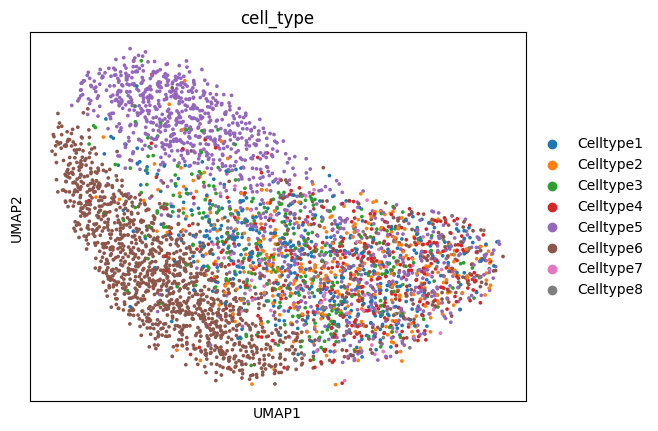

In [67]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')